# 3. Des articles aux modèles : où la France décroche-t-elle ?

On suit la France le long de la chaîne de l'IA, maillon par maillon :

| Maillon | Indicateur | Source |
|---|---|---|
| Recherche | articles en IA, et articles parmi les 1 % les plus cités | OpenAlex |
| Modèles | modèles notables, modèles de pointe | Epoch AI |
| Diffusion | téléchargements des modèles ouverts | Hugging Face |

Chaque indicateur est aussi **rapporté à la taille du pays** (population, PIB ; Banque mondiale).

**Hypothèse centrale** : la France tient son rang en recherche, mais le perd quand on passe des articles aux modèles.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import FIGURES
from style import COULEURS_PAYS, ORDRE_PAYS, appliquer_style
from nettoyage import charger_dernier, preparer_epoch, eclater_pays
appliquer_style()
FIGURES.mkdir(exist_ok=True)
PAYS = [p for p in ORDRE_PAYS if p != "Autres"]

## 0. Chargement

In [2]:
publications = charger_dernier("openalex_publications")
pays_info = charger_dernier("banque_mondiale")
epoch = eclater_pays(preparer_epoch(charger_dernier("epoch_notable_models")))
hf = charger_dernier("hf_models")

print("Publications :", publications.shape, "| années", publications["annee"].min(), "-", publications["annee"].max())
print("Banque mondiale : valeurs manquantes", pays_info.isna().sum().to_dict())

Lecture locale : data/raw/openalex_publications_2026-11-22.csv
Lecture locale : data/raw/banque_mondiale_2026-11-22.csv
Lecture locale : data/raw/epoch_notable_models_2026-11-22.csv
Lecture locale : data/raw/hf_models_2026-11-22.csv
Publications : (66, 4) | années 2015 - 2025
Banque mondiale : valeurs manquantes {'pays': 0, 'annee': 0, 'pib_usd': 0, 'population': 0}


## 1. Le maillon recherche

Un article est compté pour un pays dès qu'un de ses auteurs y est affilié : un article franco-américain compte pour les deux pays (**comptage entier**, imposé par la façon dont OpenAlex agrège). La somme des pays dépasse donc le total mondial ; on compare des niveaux, pas des parts additives.

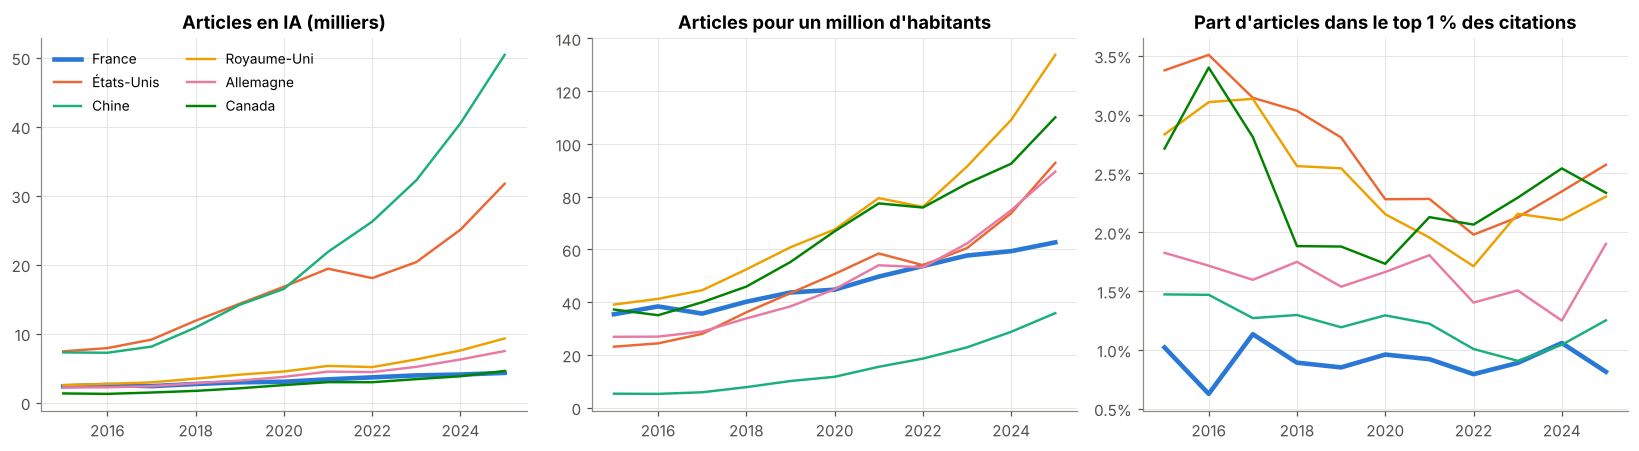

In [3]:
pub = publications.merge(pays_info, on=["pays", "annee"], how="left")
pub["par_million_hab"] = pub["publications"] / pub["population"] * 1e6
pub["part_top1"] = pub["publications_top1"] / pub["publications"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for p in PAYS:
    s = pub.loc[pub["pays"] == p].sort_values("annee")
    lw = 3 if p == "France" else 1.6
    axes[0].plot(s["annee"], s["publications"] / 1000, color=COULEURS_PAYS[p], lw=lw, label=p)
    axes[1].plot(s["annee"], s["par_million_hab"], color=COULEURS_PAYS[p], lw=lw)
    axes[2].plot(s["annee"], s["part_top1"], color=COULEURS_PAYS[p], lw=lw)
axes[0].set_title("Articles en IA (milliers)")
axes[1].set_title("Articles pour un million d'habitants")
axes[2].set_title("Part d'articles dans le top 1 % des citations")
axes[2].yaxis.set_major_formatter(lambda x, _: f"{x:.1%}")
axes[0].legend(ncol=2, fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES / "20_recherche.png")

**Interprétation.** Le classement de la France dépend beaucoup de l'indicateur. En volume, elle est derrière la Chine, les États-Unis, le Royaume-Uni et l'Allemagne, au niveau du Canada. Par habitant, elle publie presque autant que les États-Unis et l'Allemagne, mais moins que le Royaume-Uni et le Canada. En qualité, c'est là qu'elle est la plus faible : moins de 1 % de ses articles sont dans le 1 % les plus cités, contre 2,5 % pour les États-Unis et 2,4 % pour le Canada. Pour savoir si la France est en retard, l'indicateur par habitant est le plus juste pour comparer l'effort de recherche, et la part d'articles très cités pour comparer son influence.

## 2. Le maillon modèles, rapporté à la recherche

In [4]:
periodes = {"2018-2020": range(2018, 2021), "2021-2023": range(2021, 2024), "2024-2025": range(2024, 2026)}

def par_periode(df, valeur, annees):
    return df.loc[df["annee"].isin(annees)].groupby("pays")[valeur].sum()

lignes = []
for nom, annees in periodes.items():
    t = pd.DataFrame({
        "articles": par_periode(publications, "publications", annees),
        "articles_top1": par_periode(publications, "publications_top1", annees),
        "modeles": par_periode(epoch, "poids", annees),
        "modeles_pointe": par_periode(epoch.assign(p=epoch["poids"] * epoch["frontiere"]), "p", annees),
    }).reindex(PAYS).fillna(0)
    t["modeles_pour_1000_articles"] = t["modeles"] / t["articles"] * 1000
    t["periode"] = nom
    lignes.append(t)
chaine = pd.concat(lignes).reset_index(names="pays")
chaine.round(2)

,pays,articles,articles_top1,modeles,modeles_pointe,modeles_pour_1000_articles,periode
0,France,8660.0,78.0,5.70,0.0,0.66,2018-2020
1,États-Unis,43005.0,1145.0,104.93,14.0,2.44,2018-2020
2,Chine,41549.0,523.0,9.58,0.0,0.23,2018-2020
3,Royaume-Uni,12032.0,289.0,16.08,1.0,1.34,2018-2020
4,Allemagne,9725.0,160.0,3.33,0.0,0.34,2018-2020
5,Canada,6320.0,115.0,1.70,0.0,0.27,2018-2020
6,France,10972.0,95.0,8.08,0.0,0.74,2021-2023
7,États-Unis,57818.0,1233.0,178.86,16.0,3.09,2021-2023
8,Chine,80316.0,823.0,47.52,2.0,0.59,2021-2023
9,Royaume-Uni,16730.0,327.0,19.47,1.0,1.16,2021-2023


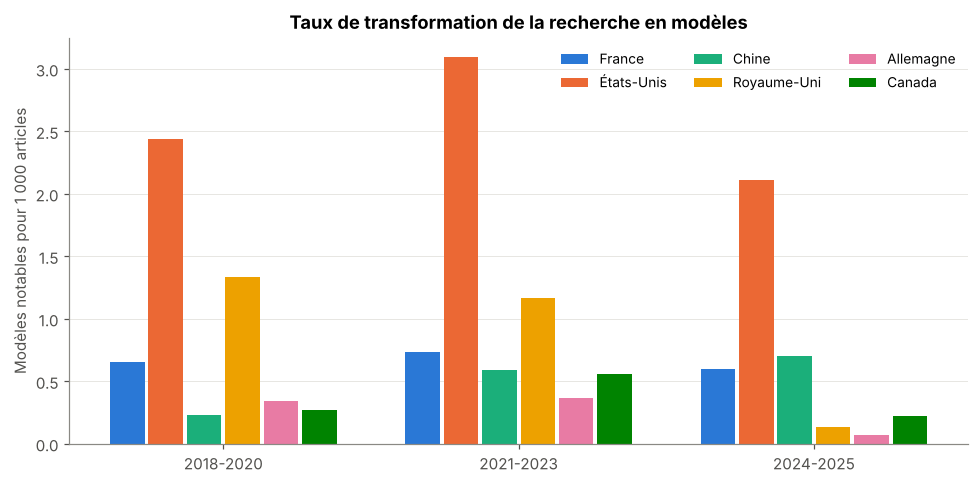

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
largeur = 0.13
x = np.arange(len(periodes))
for i, p in enumerate(PAYS):
    v = chaine.loc[chaine["pays"] == p].set_index("periode").loc[list(periodes), "modeles_pour_1000_articles"]
    ax.bar(x + (i - 2.5) * largeur, v, width=largeur * 0.9, color=COULEURS_PAYS[p], label=p)
ax.set_xticks(x, list(periodes))
ax.set_ylabel("Modèles notables pour 1 000 articles")
ax.set_title("Taux de transformation de la recherche en modèles")
ax.legend(ncol=3, fontsize=9)
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "21_transformation.png")

**Interprétation.** Oui, la France transforme beaucoup moins sa recherche en modèles que les États-Unis, avec 0,6 modèle pour 1 000 articles sur 2024-2025 contre 2,1. Elle fait en revanche mieux que l'Allemagne (0,07) et le Canada (0,23), et mieux que le Royaume-Uni sur la dernière période, même si la chute britannique vient en partie de l'attribution de Google DeepMind aux États-Unis. L'écart avec les États-Unis ne se réduit pas, alors que la Chine passe de 0,23 à 0,70 et rattrape la France.

## 3. Le maillon diffusion : qui télécharge-t-on ?

Sur Hugging Face, la part de chaque pays dans les téléchargements des modèles ouverts des organisations suivies (liste dans `src/collecte_huggingface.py`).

*Limite* : seules les organisations de la liste sont couvertes, et le champ `downloads` couvre une période récente, pas le cumul depuis la création.

In [6]:
diffusion = (hf.groupby("pays")
             .agg(modeles=("id", "count"), telechargements=("downloads", "sum"),
                  median_par_modele=("downloads", "median"))
             .reindex(PAYS).fillna(0))
diffusion["part_telechargements"] = diffusion["telechargements"] / diffusion["telechargements"].sum()
diffusion.style.format({"telechargements": "{:,.0f}", "median_par_modele": "{:,.0f}", "part_telechargements": "{:.1%}"})

,modeles,telechargements,median_par_modele,part_telechargements
pays,,,,
France,286.000000,"9,333,318",278,1.9%
États-Unis,2665.000000,"225,801,377",381,46.5%
Chine,575.000000,"243,134,274","11,586",50.0%
Royaume-Uni,120.000000,"7,614,095",803,1.6%
Allemagne,0.000000,0,0,0.0%
Canada,0.000000,0,0,0.0%


## 4. Le profil de la France, maillon par maillon

Pour chaque maillon, la part de la France parmi les six pays comparés, sur la période la plus récente. Si l'hypothèse est juste, la barre bleue doit baisser de gauche à droite.

,Articles,Articles top 1 %,Modèles notables,Modèles de pointe,Téléchargements HF
pays,,,,,
France,4.3%,2.3%,2.6%,0.0%,1.9%
États-Unis,29.1%,42.1%,61.9%,94.1%,46.5%
Chine,46.6%,31.6%,32.9%,5.9%,50.0%
Royaume-Uni,8.6%,11.2%,1.2%,0.0%,1.6%
Allemagne,7.0%,6.6%,0.5%,0.0%,0.0%
Canada,4.3%,6.1%,1.0%,0.0%,0.0%


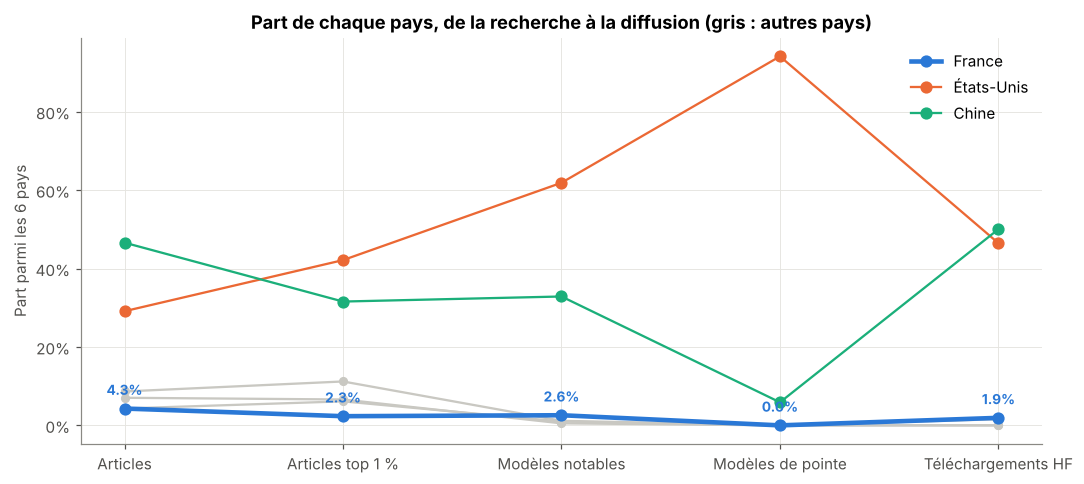

In [7]:
recent = chaine.loc[chaine["periode"] == "2024-2025"].set_index("pays")
profil = pd.DataFrame({
    "Articles": recent["articles"] / recent["articles"].sum(),
    "Articles top 1 %": recent["articles_top1"] / recent["articles_top1"].sum(),
    "Modèles notables": recent["modeles"] / recent["modeles"].sum(),
    "Modèles de pointe": recent["modeles_pointe"] / max(recent["modeles_pointe"].sum(), 1e-9),
    "Téléchargements HF": diffusion["part_telechargements"],
}).reindex(PAYS)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(profil.shape[1])
for p in PAYS:
    gris = p not in {"France", "États-Unis", "Chine"}
    ax.plot(x, profil.loc[p], marker="o", markersize=7 if not gris else 5,
            color="#c9c8c2" if gris else COULEURS_PAYS[p], lw=3 if p == "France" else 1.5,
            label=None if gris else p, zorder=1 if gris else 3)
for xi, v in zip(x, profil.loc["France"]):
    ax.annotate(f"{v:.1%}", (xi, v), textcoords="offset points", xytext=(0, 9),
                ha="center", color="#2a78d6", fontsize=9, fontweight="bold")
ax.set_xticks(x, profil.columns)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Part parmi les 6 pays")
ax.set_title("Part de chaque pays, de la recherche à la diffusion (gris : autres pays)")
ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "22_profil_chaine.png")
profil.style.format("{:.1%}")

**Interprétation.** La France décroche au passage de la recherche aux modèles. Elle pèse 4,3 % des articles des six pays mais 2,6 % des modèles notables et aucun modèle de pointe. La diffusion ne rattrape pas ce retard, puisque les modèles français ne font que 1,9 % des téléchargements sur Hugging Face, alors que la Chine dépasse désormais les États-Unis grâce à ses modèles ouverts.

## Limites

- Recherche en **comptage entier**, modèles en **comptage fractionnaire** : les deux maillons ne sont pas comptés de la même manière. Le ratio modèles / articles se lit en tendance et en comparaison entre pays, pas en valeur absolue.
- Epoch ne recense que les modèles **notables** : un pays peut produire beaucoup de modèles sans qu'aucun soit retenu.
- OpenAlex : affiliation des auteurs, pas leur nationalité. La dernière année est incomplète (délai d'indexation des publications), et la catégorie « Artificial Intelligence » contient des articles hors sujet, notamment en informatique quantique (voir le notebook 2).
- Epoch rattache un modèle au pays de son organisation, ce qui pose des questions de frontières : les modèles de Facebook AI Research sont comptés pour moitié en France (laboratoire parisien), et ceux de DeepMind passent du Royaume-Uni (« DeepMind ») aux États-Unis à partir de la fusion avec Google Brain en 2023 (« Google DeepMind »). Cela explique en partie la chute du Royaume-Uni sur la dernière période.